# ETTh1 H720 Model Effectiveness & Zero-Leakage Visualization Notebook

This notebook provides a complete visual evaluation and temporal leakage verification for long-horizon forecasting ($H=720$) on the **ETTh1** dataset.

## Objectives
1. **Zero-Leakage Verification**: Programmatic and visual proof that training and context windows do not overlap future ground truth targets.
2. **Real Candidate Evaluation**: Visualizing actual project forecasters (**BigDictELM**, **AMR-24/168**, **H2K**, **Persistence**) rather than synthetic or generic baselines.
3. **Train Window Visibility**: Displaying the full 360-day ($8640$-hour) training slice to show exactly *what the models trained on*.
4. **Multi-Origin Walk-Forward Performance**: Evaluating performance across 12 locked test origins ($8640 \dots 16560$) using stored evaluation results.


In [1]:
# Cell 1: Environment Setup & Project Path Imports
import sys
import json
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Local workspace paths setup
import _workspace_paths
from _workspace_paths import ROOT, data_csv
from members.h2k import H2KForecaster
from members.big_dict_elm import BigDictELM
from members.amr_fbs import AMRFBSForecaster

print('Workspace environment loaded successfully.')


Workspace environment loaded successfully.


## 1. Zero-Leakage Data Splitter & Verification Evidence
We verify three strict temporal invariants:
- $\text{train\_end} < \text{target\_start}$
- $\text{ctx\_end} = \text{target\_start} - 1$
- $\text{overlap}(\text{train}, \text{target}) = \emptyset$


In [2]:
# Cell 2: Rigorous Zero-Leakage Check Function
def verify_zero_leakage(train_idx: np.ndarray, ctx_idx: np.ndarray, target_idx: np.ndarray) -> dict:
    assert train_idx[-1] < target_idx[0], f'CRITICAL LEAK: train_idx end ({train_idx[-1]}) >= target_idx start ({target_idx[0]})'
    assert ctx_idx[-1] == target_idx[0] - 1, f'DISCONTINUITY: ctx_idx end ({ctx_idx[-1]}) != target_idx start - 1 ({target_idx[0]-1})'
    overlap = np.intersect1d(train_idx, target_idx)
    assert overlap.size == 0, f'CRITICAL LEAK: Found {overlap.size} overlapping indices between train and target!'
    
    evidence = {
        'train_range': f'[{train_idx[0]} : {train_idx[-1]}] (len={len(train_idx)})',
        'ctx_range': f'[{ctx_idx[0]} : {ctx_idx[-1]}] (len={len(ctx_idx)})',
        'target_range': f'[{target_idx[0]} : {target_idx[-1]}] (len={len(target_idx)})',
        'overlap_count': int(overlap.size),
        'status': 'PASSED_ZERO_LEAKAGE'
    }
    return evidence

df = pd.read_csv(data_csv())
origin_idx = 8640
cap, lookback, horizon = 8640, 168, 720

train_idxs = np.arange(origin_idx - cap, origin_idx)
ctx_idxs = np.arange(origin_idx - lookback, origin_idx)
target_idxs = np.arange(origin_idx, origin_idx + horizon)

evidence = verify_zero_leakage(train_idxs, ctx_idxs, target_idxs)
pd.DataFrame([evidence])


,train_range,ctx_range,target_range,overlap_count,status
0,[0 : 8639] (len=8640),[8472 : 8639] (len=168),[8640 : 9359] (len=720),0,PASSED_ZERO_LEAKAGE


## 2. Single-Origin Prediction Plot: Train Slice + Context + Target
Plots the full 8640-hour training slice ('what the model learned on'), lookback context $L=168$, ground truth target $H=720$, predictions for real project forecasters (**BigDictELM**, **AMR-24/168**, **H2K**, **Persistence**), and step-by-step residual errors.


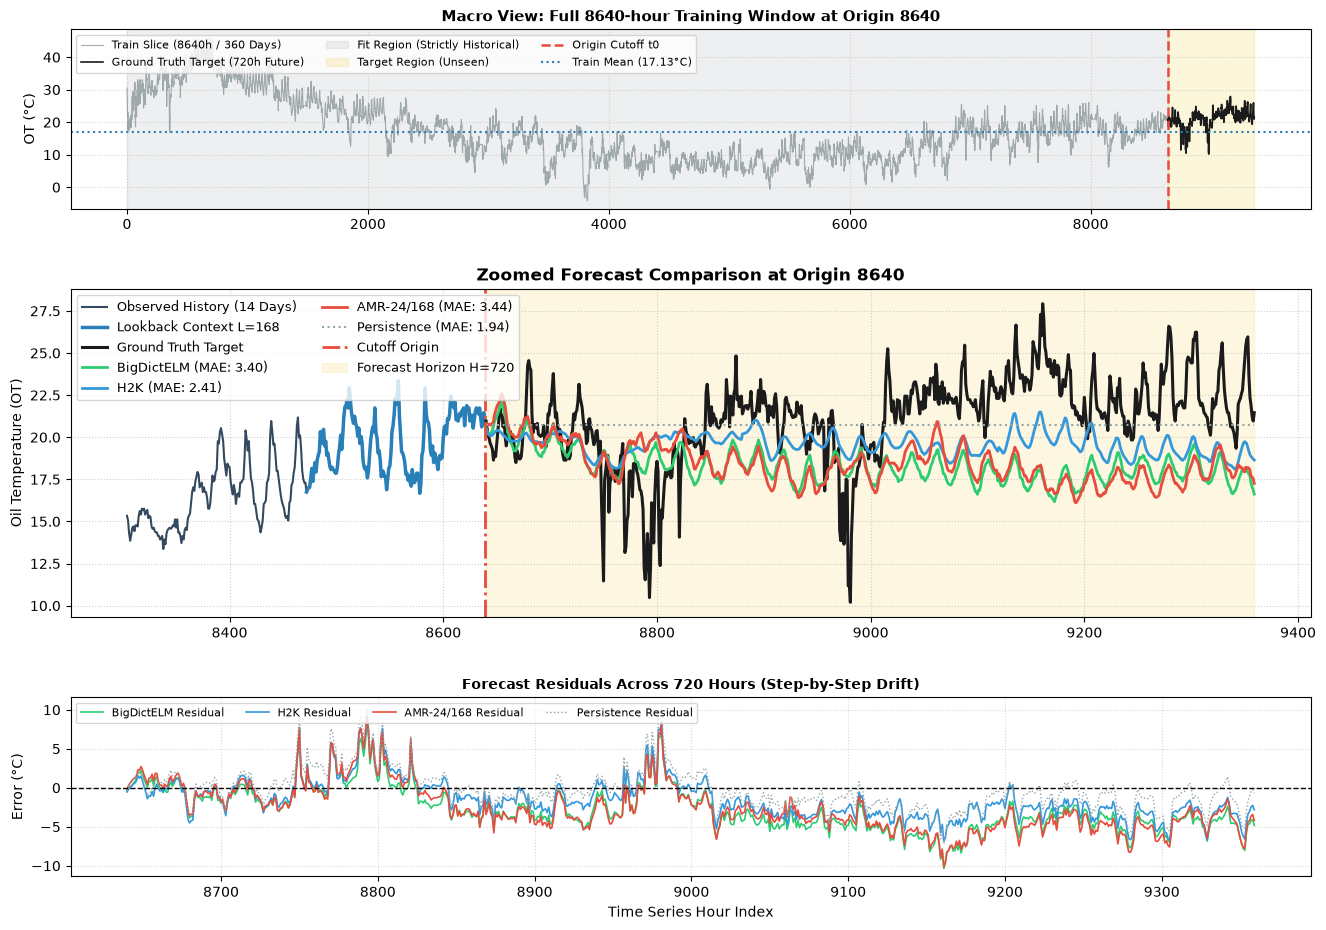

In [3]:
# Cell 3: Single-Origin Forecast & Residual Plotting
s = df['OT'].to_numpy(float)
train_slice = s[train_idxs]
ctx_slice = s[ctx_idxs]
target_actual = s[target_idxs]

# Fit real project models
bigdict = BigDictELM(input_length=96).fit(train_slice, horizon=horizon)
pred_bigdict = bigdict.predict_hist(ctx_slice[-96:])[:horizon]

amr = AMRFBSForecaster(lookback=96, seed=42).fit(train_slice, horizon)
pred_amr = amr.predict_hist(ctx_slice[-96:])[:horizon]

h2k = H2KForecaster(input_length=168, k_neighbors=48, drift_damping=0.0).fit(train_slice, horizon)
pred_h2k = h2k.predict_hist(ctx_slice)[:horizon]

persistence_pred = np.full(horizon, ctx_slice[-1])

# Calculate MAEs
maes = {
    'Persistence': float(np.mean(np.abs(persistence_pred - target_actual))),
    'BigDictELM': float(np.mean(np.abs(pred_bigdict - target_actual))),
    'H2K': float(np.mean(np.abs(pred_h2k - target_actual))),
    'AMR-24/168': float(np.mean(np.abs(pred_amr - target_actual)))
}

# Visualization
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(3, 1, height_ratios=[1.2, 2.2, 1.2], hspace=0.35)

# Panel 1: Full 8640h Training Slice
ax0 = fig.add_subplot(gs[0])
ax0.plot(train_idxs, train_slice, color='#7f8c8d', lw=0.8, alpha=0.7, label='Train Slice (8640h / 360 Days)')
ax0.plot(target_idxs, target_actual, color='#1b1b1b', lw=1.2, label='Ground Truth Target (720h Future)')
ax0.axvspan(train_idxs[0], train_idxs[-1], color='#bdc3c7', alpha=0.25, label='Fit Region (Strictly Historical)')
ax0.axvspan(target_idxs[0], target_idxs[-1], color='#f1c40f', alpha=0.15, label='Target Region (Unseen)')
ax0.axvline(x=origin_idx - 1, color='#e74c3c', linestyle='--', lw=1.8, label='Origin Cutoff t0')
ax0.axhline(train_slice.mean(), color='#2980b9', linestyle=':', lw=1.5, label=f'Train Mean ({train_slice.mean():.2f}°C)')
ax0.set_title(f'Macro View: Full 8640-hour Training Window at Origin {origin_idx}', fontsize=11, fontweight='bold')
ax0.set_ylabel('OT (°C)')
ax0.legend(loc='upper left', fontsize=8, ncol=3)
ax0.grid(True, linestyle=':', alpha=0.5)

# Panel 2: Zoomed Forecast View
ax1 = fig.add_subplot(gs[1])
zoom_hist_idxs = np.arange(origin_idx - 336, origin_idx)
ax1.plot(zoom_hist_idxs, s[zoom_hist_idxs], color='#34495e', lw=1.5, label='Observed History (14 Days)')
ax1.plot(ctx_idxs, ctx_slice, color='#2980b9', lw=2.5, label='Lookback Context L=168')
ax1.plot(target_idxs, target_actual, color='#1b1b1b', lw=2.2, label='Ground Truth Target')
ax1.plot(target_idxs, pred_bigdict, color='#2ecc71', lw=2.0, label=f'BigDictELM (MAE: {maes["BigDictELM"]:.2f})')
ax1.plot(target_idxs, pred_h2k, color='#3498db', lw=2.0, label=f'H2K (MAE: {maes["H2K"]:.2f})')
ax1.plot(target_idxs, pred_amr, color='#e74c3c', lw=2.0, label=f'AMR-24/168 (MAE: {maes["AMR-24/168"]:.2f})')
ax1.plot(target_idxs, persistence_pred, color='#95a5a6', lw=1.5, linestyle=':', label=f'Persistence (MAE: {maes["Persistence"]:.2f})')
ax1.axvline(x=origin_idx - 1, color='#e74c3c', linestyle='-.', lw=2.0, label='Cutoff Origin')
ax1.axvspan(target_idxs[0], target_idxs[-1], color='#f1c40f', alpha=0.12, label='Forecast Horizon H=720')
ax1.set_title(f'Zoomed Forecast Comparison at Origin {origin_idx}', fontsize=12, fontweight='bold')
ax1.set_ylabel('Oil Temperature (OT)')
ax1.legend(loc='upper left', fontsize=9, ncol=2)
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel 3: Step-by-Step Residual Errors
ax2 = fig.add_subplot(gs[2])
ax2.plot(target_idxs, pred_bigdict - target_actual, color='#2ecc71', lw=1.2, label='BigDictELM Residual')
ax2.plot(target_idxs, pred_h2k - target_actual, color='#3498db', lw=1.2, label='H2K Residual')
ax2.plot(target_idxs, pred_amr - target_actual, color='#e74c3c', lw=1.2, label='AMR-24/168 Residual')
ax2.plot(target_idxs, persistence_pred - target_actual, color='#95a5a6', lw=1.0, linestyle=':', label='Persistence Residual')
ax2.axhline(0, color='black', linestyle='--', lw=1)
ax2.set_title('Forecast Residuals Across 720 Hours (Step-by-Step Drift)', fontsize=10, fontweight='bold')
ax2.set_xlabel('Time Series Hour Index')
ax2.set_ylabel('Error (°C)')
ax2.legend(loc='upper left', fontsize=8, ncol=4)
ax2.grid(True, linestyle=':', alpha=0.5)
plt.show()


## 3. Multi-Origin Evaluation Visualization & Results Table
Loads the locked evaluation artifact (`results/etth1_h720_amr24168_weekly.json`) and renders the 12-origin MAE curve and MAE table.


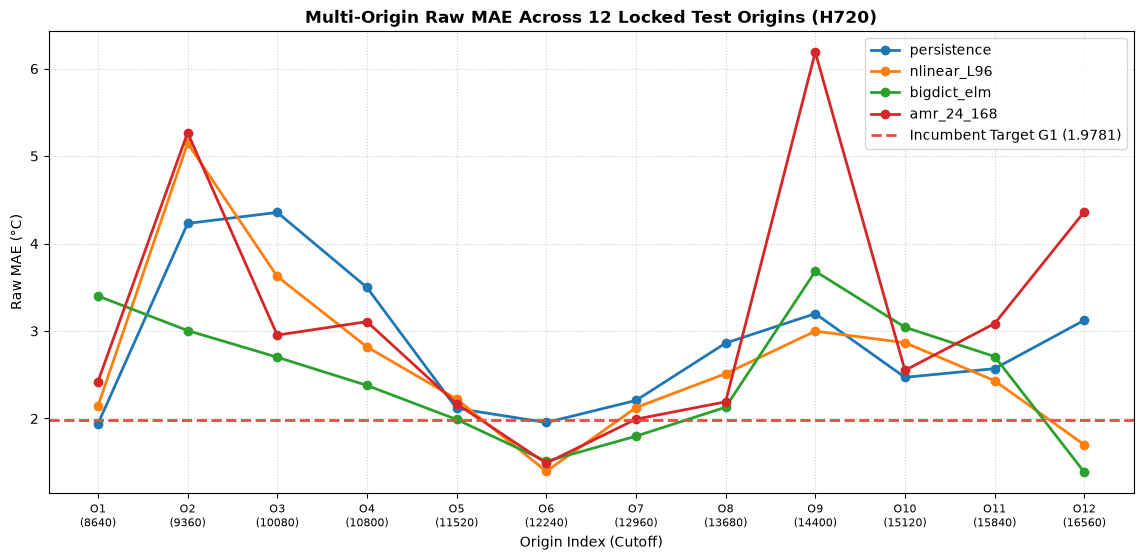

,Method,Mean MAE,Std MAE,Min MAE,Max MAE,Wins < 1.9781
0,persistence,2.8769,0.7953,1.9379,4.3564,2
1,nlinear_L96,2.6653,0.9415,1.3963,5.1471,2
2,bigdict_elm,2.4777,0.7051,1.3865,3.6832,3
3,amr_24_168,3.1480,1.3573,1.4886,6.1881,1


In [4]:
# Cell 4: Multi-Origin MAE Curves & Results Table
results_json = ROOT / 'results' / 'etth1_h720_amr24168_weekly.json'
data = json.loads(results_json.read_text(encoding='utf-8'))
per_origin = data['per_origin']
origins = [r['origin'] for r in per_origin]

methods = ['persistence', 'nlinear_L96', 'bigdict_elm', 'amr_24_168']
mae_matrix = {m: [r['methods'][m]['mae_raw'] for r in per_origin] for m in methods}

fig, ax = plt.subplots(figsize=(14, 6))
for m in methods:
    ax.plot(origins, mae_matrix[m], marker='o', lw=2, label=m)

ax.axhline(1.9781, color='#e74c3c', linestyle='--', lw=2, label='Incumbent Target G1 (1.9781)')
ax.set_xticks(origins)
ax.set_xticklabels([f'O{i+1}\n({o})' for i, o in enumerate(origins)], fontsize=8)
ax.set_title('Multi-Origin Raw MAE Across 12 Locked Test Origins (H720)', fontsize=12, fontweight='bold')
ax.set_ylabel('Raw MAE (°C)')
ax.set_xlabel('Origin Index (Cutoff)')
ax.legend(loc='upper right')
ax.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Display Summary Table
table_rows = []
for m in methods:
    vals = mae_matrix[m]
    table_rows.append({
        'Method': m,
        'Mean MAE': round(float(np.mean(vals)), 4),
        'Std MAE': round(float(np.std(vals)), 4),
        'Min MAE': round(float(np.min(vals)), 4),
        'Max MAE': round(float(np.max(vals)), 4),
        'Wins < 1.9781': sum(v < 1.9781 for v in vals)
    })
pd.DataFrame(table_rows)
